<a href="https://colab.research.google.com/github/Sai-D-beep/Quantum-computing-hackathon/blob/main/Question%20no%2012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pennylane torch scikit-learn matplotlib seaborn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 31.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 113.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 78.4 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [2]:
import pennylane as qml
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import f1_score

In [3]:
np.random.seed(42)
torch.manual_seed(42)

N_QUBITS = 2
LAYERS = 3
EPOCHS = 25
LEARNING_RATE = 0.08

print("Configuration completed")
print("Qubits:", N_QUBITS)
print("Layers:", LAYERS)

Configuration completed
Qubits: 2
Layers: 3


In [4]:
dev = qml.device(
    "default.qubit",
    wires=N_QUBITS
)

print("Quantum simulator initialized")

Quantum simulator initialized




In [6]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.axis("off")

steps = [
    "Input Data",
    "Feature Encoding",
    "Quantum Circuit",
    "Measurement",
    "Prediction"
]

colors = ["skyblue", "lightgreen", "orange",
          "plum", "gold"]

for i, step in enumerate(steps):
    x = i * 2.5

    ax.text(
        x, 0.5, step,
        ha="center",
        va="center",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.8",
            fc=colors[i],
            ec="black"
        )
    )

    if i < 4:
        ax.annotate(
            "",
            xy=(x+1.5, 0.5),
            xytext=(x+0.8, 0.5),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

plt.title("Quantum Machine Learning Workflow")
plt.show()

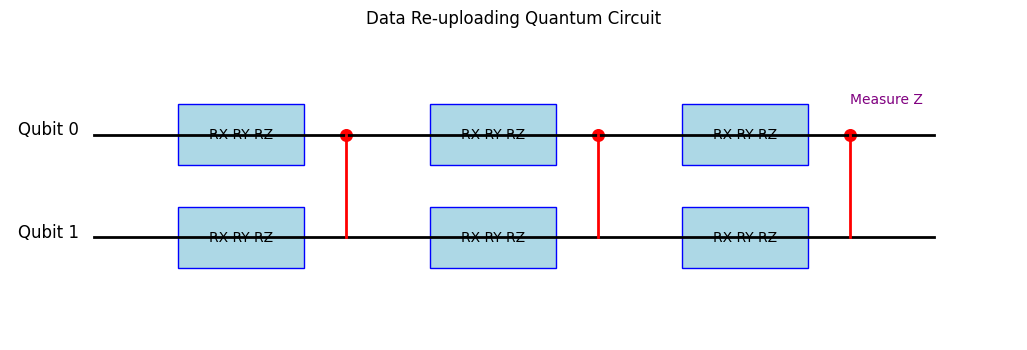

In [7]:
fig, ax = plt.subplots(figsize=(13, 4))

ax.axis("off")
ax.set_xlim(0, 12)
ax.set_ylim(0, 3)

ax.plot([1, 11], [2, 2], color="black", lw=2)
ax.plot([1, 11], [1, 1], color="black", lw=2)

ax.text(0.1, 2, "Qubit 0", fontsize=12)
ax.text(0.1, 1, "Qubit 1", fontsize=12)

for x in [2, 5, 8]:
    for y in [1, 2]:
        rect = plt.Rectangle(
            (x, y-0.3), 1.5, 0.6,
            facecolor="lightblue",
            edgecolor="blue"
        )
        ax.add_patch(rect)

        ax.text(
            x+0.75, y,
            "RX RY RZ",
            ha="center",
            va="center"
        )

    ax.plot([x+2, x+2], [1, 2], color="red", lw=2)
    ax.scatter([x+2], [2], color="red", s=70)

ax.text(10, 2.3, "Measure Z", color="purple")

plt.title("Data Re-uploading Quantum Circuit")
plt.show()

In [8]:
def quantum_layer(inputs, weights):

    for l in range(LAYERS):

        for i in range(N_QUBITS):

            qml.RX(
                inputs[i] + weights[l, i, 0],
                wires=i
            )

            qml.RY(
                inputs[i] + weights[l, i, 1],
                wires=i
            )

            qml.RZ(
                inputs[i] + weights[l, i, 2],
                wires=i
            )

        qml.CNOT(wires=[0, 1])

In [9]:
@qml.qnode(dev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):

    quantum_layer(inputs, weights)

    return qml.expval(qml.PauliZ(0))

In [10]:
test_input = torch.tensor(
    [0.2, 0.4],
    dtype=torch.float32
)

test_weights = torch.randn(
    LAYERS, N_QUBITS, 3
) * 0.1

result = quantum_circuit(
    test_input,
    test_weights
)

print("Quantum output:", result)

Quantum output: tensor(0.4713, dtype=torch.float64)


In [11]:
print(
    qml.draw(quantum_circuit)(
        test_input,
        test_weights
    )
)

0: ──RX(0.39)──RY(0.35)──RZ(0.15)─╭●──RX(0.28)──RY(0.37)──RZ(0.24)─╭●──RX(0.18)──RY(0.20) ···
1: ──RX(0.44)──RY(0.32)──RZ(0.51)─╰X──RX(0.33)──RY(0.46)──RZ(0.53)─╰X──RX(0.49)──RY(0.37) ···

0: ··· ──RZ(0.17)─╭●─┤  <Z>
1: ··· ──RZ(0.36)─╰X─┤     


In [12]:
iris = load_iris()

X_iris = iris.data[:, :2]

y_iris = (
    iris.target != 0
).astype(int)

print("Iris dataset loaded")
print("Features:", X_iris.shape)
print("Labels:", y_iris.shape)

Iris dataset loaded
Features: (150, 2)
Labels: (150,)


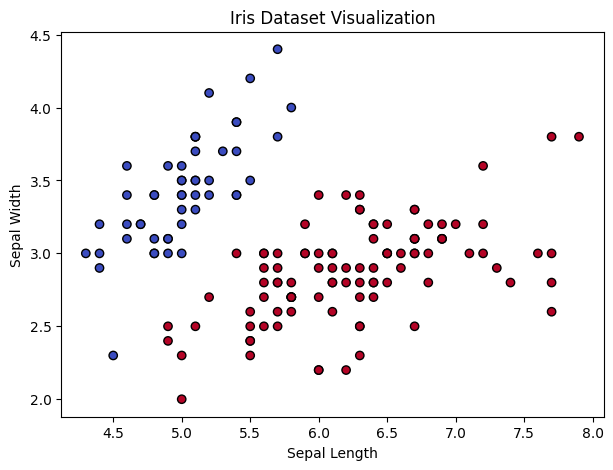

In [13]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=y_iris,
    cmap="coolwarm",
    edgecolor="black"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("Iris Dataset Visualization")

plt.show()

In [14]:
X_moons, y_moons = make_moons(
    n_samples=180,
    noise=0.15,
    random_state=42
)

print("Two Moons dataset loaded")
print("Features:", X_moons.shape)
print("Labels:", y_moons.shape)

Two Moons dataset loaded
Features: (180, 2)
Labels: (180,)


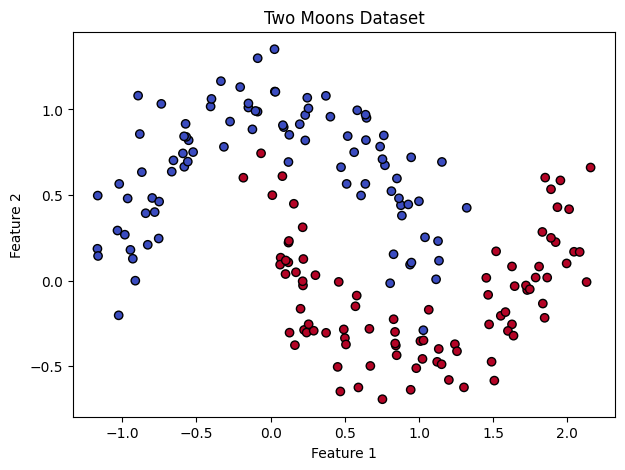

In [15]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolor="black"
)

plt.title("Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [16]:
def prepare_data(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42,
        stratify=y
    )

    scaler = MinMaxScaler(
        feature_range=(-np.pi, np.pi)
    )

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    return (
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32),
        scaler
    )

In [17]:
X_train_i, X_test_i, y_train_i, y_test_i, scaler_i = prepare_data(
    X_iris,
    y_iris
)

print("Iris training data:", X_train_i.shape)
print("Iris testing data:", X_test_i.shape)

Iris training data: torch.Size([105, 2])
Iris testing data: torch.Size([45, 2])


In [18]:
X_train_m, X_test_m, y_train_m, y_test_m, scaler_m = prepare_data(
    X_moons,
    y_moons
)

print("Moons training data:", X_train_m.shape)
print("Moons testing data:", X_test_m.shape)

Moons training data: torch.Size([126, 2])
Moons testing data: torch.Size([54, 2])


In [19]:
class QuantumClassifier(nn.Module):

    def __init__(self):

        super().__init__()

        self.weights = nn.Parameter(
            0.1 * torch.randn(
                LAYERS,
                N_QUBITS,
                3
            )
        )

    def forward(self, x):

        outputs = []

        for sample in x:

            output = quantum_circuit(
                sample,
                self.weights
            )

            outputs.append(output)

        return torch.stack(outputs)

In [20]:
model = QuantumClassifier()

print(model)
print("Quantum model created successfully")

QuantumClassifier()
Quantum model created successfully


In [21]:
def train_model(X_train, y_train):

    model = QuantumClassifier()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    loss_function = nn.BCEWithLogitsLoss()

    losses = []

    for epoch in range(EPOCHS):

        optimizer.zero_grad()

        output = model(X_train)

        loss = loss_function(
            3.0 * output,
            y_train
        )

        loss.backward()

        optimizer.step()

        losses.append(loss.item())

        if (epoch + 1) % 5 == 0:
            print(
                "Epoch:",
                epoch + 1,
                "Loss:",
                round(loss.item(), 4)
            )

    return model, losses

In [22]:
start = time.time()

iris_model, iris_losses = train_model(
    X_train_i,
    y_train_i
)

iris_time = time.time() - start

print("Iris training completed")
print("Time:", round(iris_time, 2), "seconds")

Epoch: 5 Loss: 0.626
Epoch: 10 Loss: 0.4113
Epoch: 15 Loss: 0.4107
Epoch: 20 Loss: 0.3833
Epoch: 25 Loss: 0.3542
Iris training completed
Time: 52.16 seconds


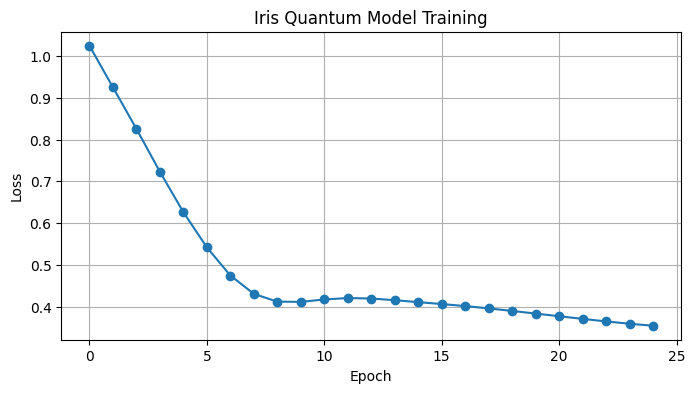

In [23]:
plt.figure(figsize=(8, 4))

plt.plot(
    iris_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Iris Quantum Model Training")

plt.grid()
plt.show()

In [24]:
start = time.time()

moons_model, moons_losses = train_model(
    X_train_m,
    y_train_m
)

moons_time = time.time() - start

print("Two Moons training completed")
print("Time:", round(moons_time, 2), "seconds")

Epoch: 5 Loss: 0.6271
Epoch: 10 Loss: 0.4758
Epoch: 15 Loss: 0.4285
Epoch: 20 Loss: 0.4138
Epoch: 25 Loss: 0.3864
Two Moons training completed
Time: 51.92 seconds


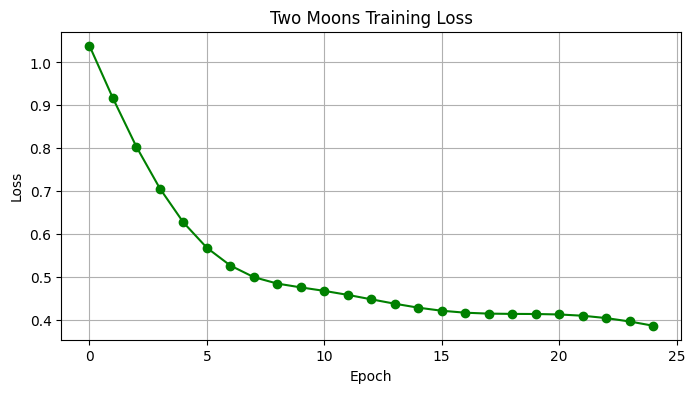

In [25]:
plt.figure(figsize=(8, 4))

plt.plot(
    moons_losses,
    marker="o",
    color="green"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Two Moons Training Loss")

plt.grid()
plt.show()

In [26]:
def evaluate_model(model, X_test, y_test):

    model.eval()

    with torch.no_grad():

        output = model(X_test)

        probabilities = torch.sigmoid(
            3.0 * output
        ).numpy()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    actual = y_test.numpy().astype(int)

    print("Accuracy:",
          accuracy_score(actual, predictions))

    print("F1 Score:",
          f1_score(actual, predictions))

    print("\nClassification Report")

    print(
        classification_report(
            actual,
            predictions,
            zero_division=0
        )
    )

    return actual, predictions, probabilities

In [27]:
y_true_i, y_pred_i, y_prob_i = evaluate_model(
    iris_model,
    X_test_i,
    y_test_i
)

Accuracy: 0.8444444444444444
F1 Score: 0.8771929824561403

Classification Report
              precision    recall  f1-score   support

           0       0.72      0.87      0.79        15
           1       0.93      0.83      0.88        30

    accuracy                           0.84        45
   macro avg       0.82      0.85      0.83        45
weighted avg       0.86      0.84      0.85        45



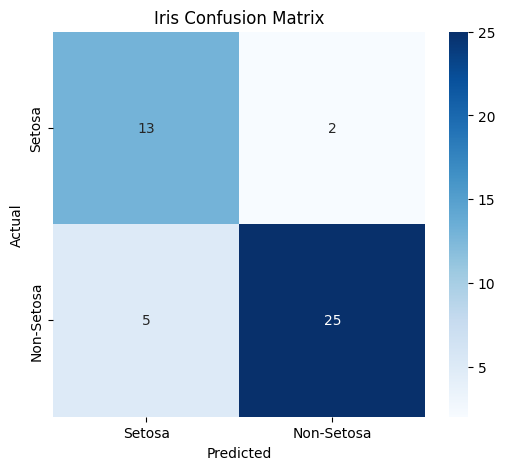

In [28]:
cm = confusion_matrix(
    y_true_i,
    y_pred_i
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Setosa", "Non-Setosa"],
    yticklabels=["Setosa", "Non-Setosa"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris Confusion Matrix")

plt.show()

In [29]:
y_true_m, y_pred_m, y_prob_m = evaluate_model(
    moons_model,
    X_test_m,
    y_test_m
)

Accuracy: 0.7037037037037037
F1 Score: 0.75

Classification Report
              precision    recall  f1-score   support

           0       0.82      0.52      0.64        27
           1       0.65      0.89      0.75        27

    accuracy                           0.70        54
   macro avg       0.74      0.70      0.69        54
weighted avg       0.74      0.70      0.69        54



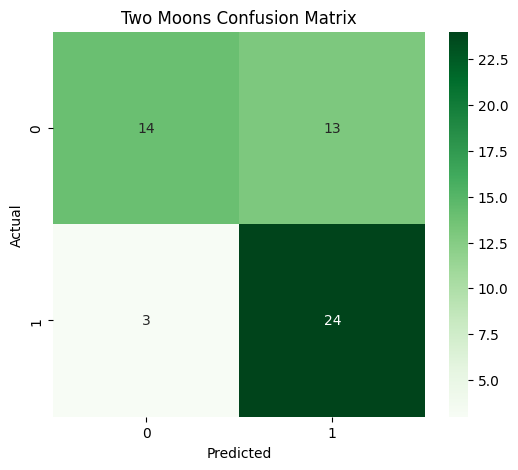

In [30]:
cm = confusion_matrix(
    y_true_m,
    y_pred_m
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Two Moons Confusion Matrix")

plt.show()

In [31]:
def plot_boundary(model, X, y, title):

    x_min = X[:, 0].min() - 0.2
    x_max = X[:, 0].max() + 0.2

    y_min = X[:, 1].min() - 0.2
    y_max = X[:, 1].max() + 0.2

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 25),
        np.linspace(y_min, y_max, 25)
    )

    grid = torch.tensor(
        np.c_[xx.ravel(), yy.ravel()],
        dtype=torch.float32
    )

    model.eval()

    with torch.no_grad():

        output = model(grid)

        predictions = torch.sigmoid(
            3.0 * output
        ).numpy()

    predictions = predictions.reshape(
        xx.shape
    )

    plt.figure(figsize=(8, 5))

    plt.contourf(
        xx,
        yy,
        predictions,
        levels=20,
        cmap="coolwarm",
        alpha=0.6
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolor="black"
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    plt.show()

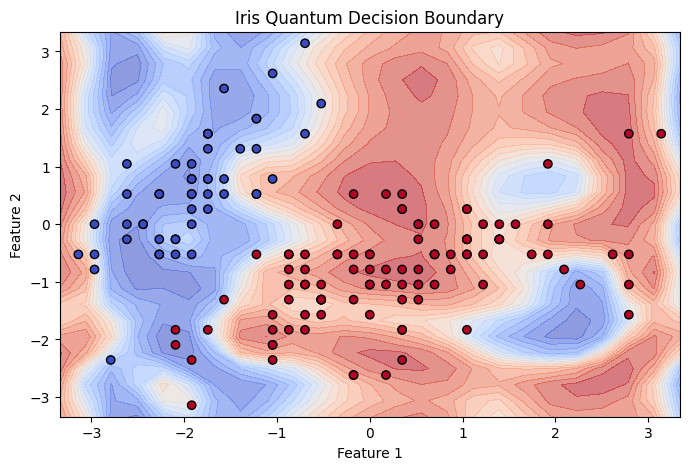

In [32]:
X_iris_scaled = scaler_i.transform(X_iris)

plot_boundary(
    iris_model,
    X_iris_scaled,
    y_iris,
    "Iris Quantum Decision Boundary"
)

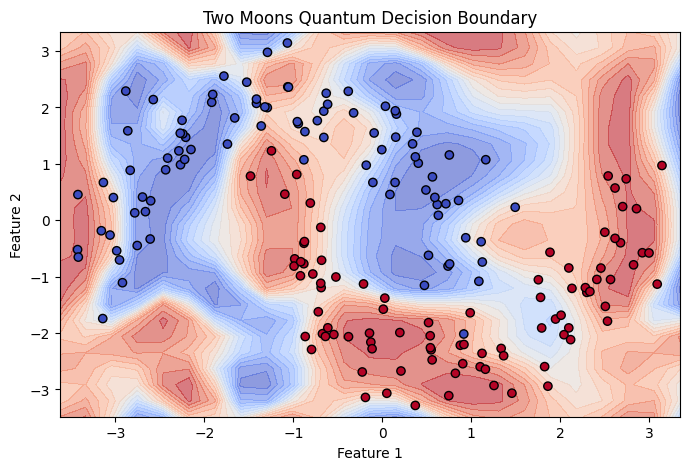

In [33]:
X_moons_scaled = scaler_m.transform(X_moons)

plot_boundary(
    moons_model,
    X_moons_scaled,
    y_moons,
    "Two Moons Quantum Decision Boundary"
)

In [34]:
iris_accuracy = accuracy_score(
    y_true_i,
    y_pred_i
)

moons_accuracy = accuracy_score(
    y_true_m,
    y_pred_m
)

results = pd.DataFrame({

    "Dataset": [
        "Iris",
        "Two Moons"
    ],

    "Accuracy": [
        iris_accuracy,
        moons_accuracy
    ],

    "Training Time": [
        iris_time,
        moons_time
    ]
})

display(results)

,Dataset,Accuracy,Training Time
0,Iris,0.844444,52.156975
1,Two Moons,0.703704,51.917089


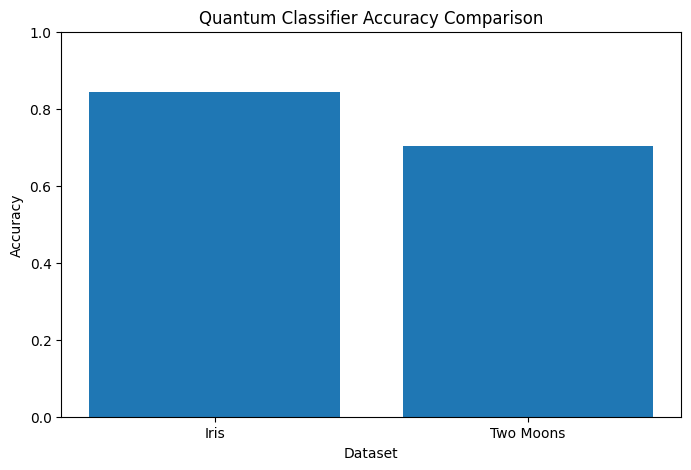

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Dataset"],
    results["Accuracy"]
)

plt.ylim(0, 1)

plt.xlabel("Dataset")
plt.ylabel("Accuracy")

plt.title("Quantum Classifier Accuracy Comparison")

plt.show()

In [36]:
print("=" * 50)

print("QUANTUM MACHINE LEARNING PROJECT")

print("=" * 50)

print("Project: Quantum Classifier with Data Re-uploading")

print("Quantum Simulator: PennyLane")

print("Qubits:", N_QUBITS)

print("Quantum Layers:", LAYERS)

print("Quantum Gates: RX, RY, RZ, CNOT")

print("Measurement: Pauli-Z")

print("-" * 50)

print("IRIS ACCURACY:",
      round(iris_accuracy * 100, 2), "%")

print("TWO MOONS ACCURACY:",
      round(moons_accuracy * 100, 2), "%")

print("-" * 50)

print("PROJECT EXECUTION COMPLETED")

print("=" * 50)

QUANTUM MACHINE LEARNING PROJECT
Project: Quantum Classifier with Data Re-uploading
Quantum Simulator: PennyLane
Qubits: 2
Quantum Layers: 3
Quantum Gates: RX, RY, RZ, CNOT
Measurement: Pauli-Z
--------------------------------------------------
IRIS ACCURACY: 84.44 %
TWO MOONS ACCURACY: 70.37 %
--------------------------------------------------
PROJECT EXECUTION COMPLETED
